# 決定木と過学習
「はい / いいえ」の質問をくり返して予測する決定木を学びます。木を深くするほど学習用のデータにはよく当てはまる一方で、検証用のデータでの精度が下がる「過学習」を確かめ、木の深さなどで複雑さを調整します。

## 学習目標
- 決定木が予測するしくみを、木の図から説明できる
- 木の深さ(`max_depth`)を変えたときの、学習用と検証用の正解率の変化を調べられる
- 過学習とは何かを説明し、学習用と検証用の正解率の差から見つけられる
- `max_depth`・`min_samples_leaf` で木の複雑さを調整できる

## 決定木のしくみ

決定木は、「性別は女性か?」「等級は 2 以下か?」のような質問でデータを分けていき、最後にたどり着いたグループで多い方の答えを予測します。深さ 2 の木を学習させて、図に描いてみます。

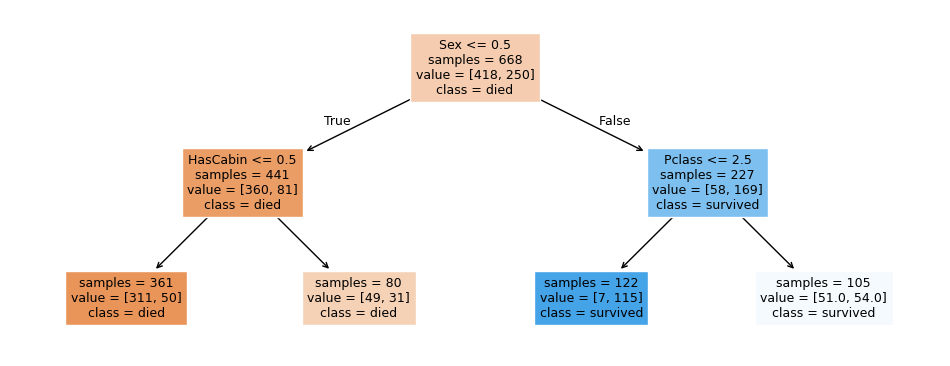

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

# 特徴量の表を読み込み、学習用と検証用に分ける(これまでと同じ分け方)
df = pd.read_csv("train_prepared.csv")
X = df.drop(columns=["PassengerId", "Survived"])
y = df["Survived"]
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)

# 深さ 2 の決定木を学習させる(random_state で結果を毎回同じにする)
tree = DecisionTreeClassifier(max_depth=2, random_state=0)
tree.fit(X_train, y_train)

# 木を図に描く(class_names はクラス 0 / 1 の表示名、filled=True で多い方のクラスの色で塗る)
fig, ax = plt.subplots(figsize=(12, 4.5))
plot_tree(tree, feature_names=list(X.columns), class_names=["died", "survived"], filled=True, impurity=False, fontsize=9, ax=ax)
plt.show()

図の読み方:

- 一番上の箱が最初の質問です。`Sex <= 0.5`(性別が 0 = 男性)が当てはまれば左(True)、当てはまらなければ(女性なら)右(False)に進みます
- `samples` はその箱に入った乗客の人数、`value` は [死亡, 生存] の人数、`class` はその箱で多い方の答えです
- 一番下の箱(葉)にたどり着いたら、その `class` を予測します

最初の質問が性別なのは、性別で生存率が最も大きく分かれるためです。女性はさらに等級(`Pclass <= 2.5`:1 等・2 等かどうか)で分かれ、1 等・2 等の女性は 122 人中 115 人が生存しています。

## 木の深さと過学習

木を深くするほど、質問の数が増え、学習用のデータに細かく当てはまるようになります。深さ 1〜10 と、深さを制限しない場合について、学習用と検証用の正解率を比べます。

深さの制限なし: 深さ 19 学習用 0.978 検証用 0.731


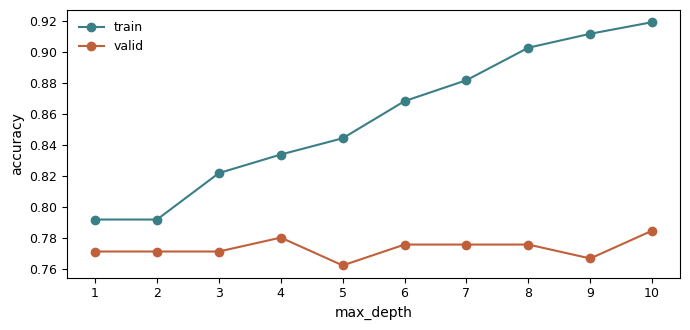

In [2]:
depths = list(range(1, 11))
train_scores = []
valid_scores = []
for depth in depths:
    # 深さを指定して学習させ、学習用・検証用の正解率を記録する
    model = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(X_train, y_train)
    train_scores.append(model.score(X_train, y_train))
    valid_scores.append(model.score(X_valid, y_valid))

# 深さを制限しない木
full = DecisionTreeClassifier(random_state=0).fit(X_train, y_train)
print("深さの制限なし: 深さ", full.get_depth(), "学習用", round(full.score(X_train, y_train), 3), "検証用", round(full.score(X_valid, y_valid), 3))

# 深さごとの正解率を折れ線グラフにする
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(depths, train_scores, marker="o", label="train")
ax.plot(depths, valid_scores, marker="o", label="valid")
ax.set_xlabel("max_depth")
ax.set_ylabel("accuracy")
ax.set_xticks(depths)
ax.legend()
fig.tight_layout()
plt.show()

- 深くするほど、学習用の正解率は上がり続けます(深さの制限なしでは 97.8%)
- 検証用の正解率は 77〜79% 前後で頭打ちになり、深さの制限なしでは 73.1% まで下がります

このように、学習用のデータに当てはまりすぎて、新しいデータでの精度が下がることを **過学習** といいます。深さの制限のない木は、学習用のデータの細かい特徴(偶然のばらつき)まで覚えてしまっています。**学習用と検証用の正解率の差が大きい** ときは、過学習を疑います。

## 複雑さを調整する

決定木の複雑さは、次のような設定(**ハイパーパラメータ**)で調整します。

| ハイパーパラメータ | 意味 | 大きくすると |
|---|---|---|
| `max_depth` | 木の深さの上限 | 複雑になる(過学習しやすい) |
| `min_samples_leaf` | 葉(一番下の箱)に入る人数の最小値 | 単純になる(過学習しにくい) |

## 演習

深さを制限せず、`min_samples_leaf=5`(葉に入る人数を 5 人以上にする)とした決定木を学習させ、学習用と検証用の正解率を、この順に小数第3位まで表示してください。

In [ ]:
# @starter
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

# 特徴量の表を読み込み、学習用と検証用に分ける
df = pd.read_csv("train_prepared.csv")
X = df.drop(columns=["PassengerId", "Survived"])
y = df["Survived"]
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)

# 葉に入る人数を 5 人以上にした決定木を作り、学習させる(____ に、ハイパーパラメータの指定を書く)
model = DecisionTreeClassifier(____, random_state=0)
model.fit(X_train, y_train)

# 学習用・検証用の正解率を表示する
print(round(model.score(X_train, y_train), 3))
print(round(model.score(X_valid, y_valid), 3))

In [3]:
# @solution
# @title: 葉の人数を制限した決定木
# @hint: DecisionTreeClassifier(min_samples_leaf=5, random_state=0) のように、引数でハイパーパラメータを指定します。
# @explanation: 学習用の正解率は 88.3% に下がり(制限なしは 97.8%)、検証用の正解率は 78.9% に上がりました(制限なしは 73.1%)。葉の人数を制限することで、少人数の細かい特徴を覚えにくくなり、過学習が抑えられました。
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

# 特徴量の表を読み込み、学習用と検証用に分ける
df = pd.read_csv("train_prepared.csv")
X = df.drop(columns=["PassengerId", "Survived"])
y = df["Survived"]
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)

# 葉に入る人数を 5 人以上(min_samples_leaf=5)にした決定木を作り、学習させる
model = DecisionTreeClassifier(min_samples_leaf=5, random_state=0)
model.fit(X_train, y_train)

# 学習用・検証用の正解率を表示する
print(round(model.score(X_train, y_train), 3))
print(round(model.score(X_valid, y_valid), 3))

0.883
0.789


深さ 1〜6 の決定木について、深さごとに **検証用の正解率** を求め、検証用の正解率が最も高い深さとその正解率(小数第3位まで)を表示してください。同じ正解率の深さが複数あるときは、最も浅い深さを選びます。

In [ ]:
# @starter
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

# 特徴量の表を読み込み、学習用と検証用に分ける
df = pd.read_csv("train_prepared.csv")
X = df.drop(columns=["PassengerId", "Survived"])
y = df["Survived"]
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)

# 深さ → 検証用の正解率 の辞書を作る
scores = {}
for depth in range(1, 7):
    model = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(X_train, y_train)
    scores[depth] = ____  # ____ に、検証用の正解率を求める式を書く

# 正解率が最も高い深さ(同じなら最も浅い深さ)を求めて表示する
best_depth = max(scores, key=scores.get)
print(best_depth, round(scores[best_depth], 3))

In [4]:
# @solution
# @title: 検証用の正解率が最も高い深さ
# @hint: 検証用の正解率は model.score(X_valid, y_valid) です。max(辞書, key=辞書.get) で、値が最大のキー(最初に見つかったもの)が求まります。
# @explanation: 深さ 4 のときに検証用の正解率が最も高く、78.0% です。ただし、深さによる差は 1〜2% と小さく、検証用のデータの分け方によって変わる可能性があります。このようなときは、単元6の交差検証で比べるとより確かです。
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

# 特徴量の表を読み込み、学習用と検証用に分ける
df = pd.read_csv("train_prepared.csv")
X = df.drop(columns=["PassengerId", "Survived"])
y = df["Survived"]
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)

# 深さ → 検証用の正解率 の辞書を作る
scores = {}
for depth in range(1, 7):
    model = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(X_train, y_train)
    scores[depth] = model.score(X_valid, y_valid)

# max(辞書, key=辞書.get) で、正解率が最も高い深さ(同じなら先に見つかった浅い方)を求める
best_depth = max(scores, key=scores.get)
print(best_depth, round(scores[best_depth], 3))

4 0.78


<!-- @question
type: choice
answer: 学習用のデータに当てはまりすぎて、新しいデータでの精度が下がっている(過学習)。
title: 過学習の判断
hint: 学習用と検証用の正解率の差に注目します。
explanation: 学習用ではほぼ全員を正しく予測できているのに、検証用では大きく下がっています。学習用のデータの細かい特徴まで覚えてしまい、新しいデータに当てはまらなくなっている状態(過学習)です。木の深さを制限するなど、モデルを単純にすると改善することがあります。
-->
ある決定木の正解率は、学習用のデータで 97.8%、検証用のデータで 73.1% だった。この状態の説明として最も適切なものを選べ。

- モデルが単純すぎて、学習用のデータの特徴をとらえきれていない。
- 学習用のデータに当てはまりすぎて、新しいデータでの精度が下がっている(過学習)。
- 検証用のデータの正解が間違っている。
- 学習用の正解率が高いので、このモデルが最もよいモデルである。

## まとめ

- 決定木は「はい / いいえ」の質問でデータを分け、葉で多い方の答えを予測する。`plot_tree` で図にできる。
- 木を深くするほど学習用の正解率は上がるが、検証用の正解率は下がることがある(過学習)。学習用と検証用の正解率の差に注意する。
- `max_depth`・`min_samples_leaf` などのハイパーパラメータで、モデルの複雑さを調整する。